# Análise de redes sociais com grafos
**Teoria e Aplicação de Grafos, Turma 01 - UnB - 2026/2**

| Integrante | Matrícula |
|---|---|
| Igor Araújo Rodrigues | 242001517 |
| Eduardo Marques Pereira | 211021004 |
| Matheus Barbosa e Silva | 190113987 |

Objetivo: representar uma amostra da rede do Facebook, comparar quatro centralidades,
detectar comunidades por Louvain e analisar o potencial de influência dos usuários.

## Instruções de execução
1. Abra este notebook na pasta do projeto, com a pasta `facebook/` ao lado.
2. Use o Python da `.venv` criada com `python3 -m venv .venv` e instale as dependências com
   `.venv/bin/python -m pip install -r requirements.txt`.
3. Inicie `.venv/bin/jupyter notebook projeto1.ipynb` e execute **Kernel > Restart Kernel and Run All Cells**.
4. As tabelas e figuras serão salvas em `resultados/`. O relatório pode ser recriado com
   `.venv/bin/python gerar_relatorio.py` depois de executar este notebook.

No Colab, obtenha a pasta `facebook/` antes de executar (ela pode ser enviada e descompactada
ou copiada do repositório do grupo). Para as células de análise bastam `networkx`, `pandas`
e `matplotlib`. O notebook contém todo o código de análise, sem importar `projeto1.py`.
A semente **1306308606** preserva o sorteio.

In [14]:
import os
import random
import json
from pathlib import Path

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import ConnectionPatch

PASTA_DADOS = Path.cwd() / "facebook"
QUANTIDADE_NOS = 404
SEMENTE = 1306308606
PASTA_RESULTADOS = Path.cwd() / "resultados"
INTEGRANTES = [
    ("Igor Araújo Rodrigues", "242001517"),
    ("Eduardo Marques Pereira", "211021004"),
    ("Matheus Barbosa e Silva", "190113987"),
]
METRICAS = {
    "centralidade_grau": "Centralidade de grau",
    "intermediacao": "Centralidade de intermediação",
    "proximidade": "Centralidade de proximidade",
    "autovetor": "Centralidade de autovetor",
}



from IPython.display import display, Image

if not PASTA_DADOS.is_dir():
    raise FileNotFoundError("Coloque a pasta facebook/ no mesmo diretório do notebook.")

## 1. Coletar dados e construir o grafo
O conjunto [ego-Facebook do SNAP](https://snap.stanford.edu/data/egonets-Facebook.html)
tem dez redes-ego. `X.edges` lista amizades entre os amigos de X. A primeira coluna de
`X.feat` identifica esses amigos. Acrescentamos as arestas `(X, amigo)` e unimos as redes.
Usamos `nx.Graph`: amizade é recíproca, sem direção ou pesos, e arestas repetidas são unificadas.

In [15]:
def listar_egos(pasta):
    return sorted(int(nome.split(".")[0]) for nome in os.listdir(pasta) if nome.endswith(".edges"))


def ler_arestas_ego(pasta, ego):
    arestas = []
    with open(os.path.join(pasta, f"{ego}.edges")) as arquivo:
        for linha in arquivo:
            u, v = linha.split()
            arestas.append((int(u), int(v)))
    # O ego é ligado a todos os amigos listados em X.feat
    with open(os.path.join(pasta, f"{ego}.feat")) as arquivo:
        for linha in arquivo:
            amigo = int(linha.split()[0])
            arestas.append((ego, amigo))
    return arestas


def construir_rede_completa(pasta):
    rede_completa = nx.Graph()
    for ego in listar_egos(pasta):
        rede_completa.add_edges_from(ler_arestas_ego(pasta, ego))
    return rede_completa


def sortear_nos(rede_completa, quantidade, semente):
    sorteador = random.Random(semente)
    return sorteador.sample(sorted(rede_completa.nodes()), quantidade)


def extrair_arestas(rede_completa, nos_sorteados):
    conjunto_sorteados = set(nos_sorteados)
    return [
        (u, v) for u, v in rede_completa.edges() if u in conjunto_sorteados and v in conjunto_sorteados
    ]


# 2. Construir grafo

def construir_grafo(tabela_nos, tabela_arestas):
    grafo = nx.Graph()
    grafo.add_nodes_from(tabela_nos["no"])
    grafo.add_edges_from(tabela_arestas.itertuples(index=False, name=None))
    return grafo

In [16]:
rede_completa = construir_rede_completa(PASTA_DADOS)
print("Egos:", listar_egos(PASTA_DADOS))
print("Nós da rede completa:", len(rede_completa))
print("Arestas da rede completa:", rede_completa.number_of_edges())
assert len(rede_completa) == 4039
assert rede_completa.number_of_edges() == 88234

Egos: [0, 107, 348, 414, 686, 698, 1684, 1912, 3437, 3980]
Nós da rede completa: 4039
Arestas da rede completa: 88234


### Sorteio dos 404 usuários
O sorteio é uniforme, sem reposição e reproduzível. Mantemos somente as arestas cujas duas
extremidades foram sorteadas: o **subgrafo induzido**. Acrescentamos todos os nós, inclusive
isolados, para manter exatamente 404 usuários. A lista salva em CSV registra a seleção;
a semente fixa tenta garantir que nenhum outro grupo tenha usado a mesma amostra.

In [17]:
nos_sorteados = sortear_nos(rede_completa, QUANTIDADE_NOS, SEMENTE)
arestas_sorteadas = extrair_arestas(rede_completa, nos_sorteados)
tabela_nos = pd.DataFrame({"no": sorted(nos_sorteados)})
tabela_arestas = pd.DataFrame(arestas_sorteadas, columns=["origem", "destino"])
grafo = construir_grafo(tabela_nos, tabela_arestas)
assert len(grafo) == QUANTIDADE_NOS
assert len(set(nos_sorteados)) == QUANTIDADE_NOS
print("Nós:", len(grafo), "| Arestas:", grafo.number_of_edges())
print("Densidade:", nx.density(grafo))
print("Isolados:", nx.number_of_isolates(grafo))
print("Componentes conexas:", nx.number_connected_components(grafo))
print("Maior componente:", len(max(nx.connected_components(grafo), key=len)))
display(tabela_arestas.head())
display(pd.Series(dict(grafo.degree()), name="grau").describe())

Nós: 404 | Arestas: 885
Densidade: 0.010871434537994742
Isolados: 74
Componentes conexas: 109
Maior componente: 142


,origem,destino
0,285,60
1,285,98
2,285,170
3,285,323
4,285,203


count    404.000000
mean       4.381188
std        5.430659
min        0.000000
25%        1.000000
50%        2.000000
75%        6.000000
max       26.000000
Name: grau, dtype: float64

## 2. Calcular as quatro centralidades
- **Grau:** número de vizinhos dividido por `N-1`; indica alcance direto.
- **Intermediação:** participação nos caminhos mínimos entre outros nós; indica posição de ligação.
- **Proximidade:** inverso da distância média aos alcançáveis, com correção de Wasserman-Faust pela
  fração alcançável. O grafo é desconectado, então não há distância finita entre todos os pares.
- **Autovetor:** valoriza ligações com nós também centrais. Usamos a iteração de potência, até
  1.000 iterações e tolerância `1e-10`. Em um grafo desconectado, os valores globais podem se
  concentrar numa componente. Valores quase zero nas demais não significam irrelevância local.

Todas as medidas usam os 404 nós. Isolados recebem zero nas quatro centralidades.

In [18]:
def calcular_metricas(grafo):
    # As medidas são calculadas sobre os 404 nós, incluindo os isolados.
    grau = nx.degree_centrality(grafo)
    intermediacao = nx.betweenness_centrality(grafo, normalized=True)
    # A correção WF reduz o valor de nós que alcançam apenas uma pequena componente.
    proximidade = nx.closeness_centrality(grafo, wf_improved=True)
    autovetor = nx.eigenvector_centrality(grafo, max_iter=1000, tol=1e-10)
    # Para isolados, o valor teórico é zero; eliminamos resíduos numéricos.
    for no in nx.isolates(grafo):
        autovetor[no] = 0.0

    componentes = sorted(nx.connected_components(grafo), key=lambda c: (-len(c), min(c)))
    componente_por_no = {no: i for i, c in enumerate(componentes) for no in c}
    return pd.DataFrame([
        {
            "no": no, "grau": grafo.degree(no),
            "centralidade_grau": grau[no], "intermediacao": intermediacao[no],
            "proximidade": proximidade[no], "autovetor": autovetor[no],
            "componente": componente_por_no[no],
            "tamanho_componente": len(componentes[componente_por_no[no]]),
        }
        for no in sorted(grafo)
    ])

In [19]:
tabela_metricas = calcular_metricas(grafo)
display(tabela_metricas.head())

,no,grau,centralidade_grau,intermediacao,proximidade,autovetor,componente,tamanho_componente
0,5,1,0.002481,0.000000,0.002481,4.427816e-153,17,2
1,7,2,0.004963,0.000222,0.016287,2.273364e-67,3,20
2,38,1,0.002481,0.000000,0.012271,3.773962e-68,3,20
3,47,0,0.000000,0.000000,0.000000,0.000000e+00,35,1
4,56,11,0.027295,0.000604,0.029859,3.901413e-66,3,20


## 3. Detectar comunidades por Louvain
Usamos a implementação do NetworkX, resolução 1 e semente fixa. Louvain alterna movimentos
locais que melhoram a modularidade e agregação das comunidades em uma rede menor. É uma
heurística, sem garantia de ótimo global. A modularidade compara as ligações internas com
as esperadas em um modelo aleatório que preserva os graus.

Numeramos as comunidades em ordem decrescente de tamanho. Cada isolado fica em uma comunidade
unitária. Comunidades e componentes conexas são conceitos diferentes.

In [20]:
def detectar_comunidades(grafo, semente):
    comunidades = nx.community.louvain_communities(grafo, seed=semente, resolution=1)
    # A numeração por tamanho facilita a leitura e não altera a partição.
    comunidades.sort(key=lambda c: (-len(c), min(c)))
    comunidade_por_no = {no: i for i, c in enumerate(comunidades) for no in c}
    tabela = pd.DataFrame([
        {"comunidade": i, "quantidade_nos": len(c),
         "arestas_internas": grafo.subgraph(c).number_of_edges()}
        for i, c in enumerate(comunidades)
    ])
    modularidade = nx.community.modularity(grafo, comunidades)
    return comunidade_por_no, tabela, modularidade


def ranking(tabela_metricas, metrica, quantidade=10):
    # Em caso de empate, ordenamos pelo identificador do nó.
    return tabela_metricas.sort_values([metrica, "no"], ascending=[False, True]).head(quantidade)

In [21]:
comunidade_por_no, tabela_comunidades, modularidade = detectar_comunidades(grafo, SEMENTE)
tabela_metricas["comunidade"] = tabela_metricas["no"].map(comunidade_por_no)
print("Comunidades:", len(tabela_comunidades))
print("Comunidades unitárias:", (tabela_comunidades["quantidade_nos"] == 1).sum())
print("Modularidade:", modularidade)
display(tabela_comunidades.head(10))
for metrica, titulo in METRICAS.items():
    print(titulo)
    display(ranking(tabela_metricas, metrica)[["no", "grau", metrica, "comunidade"]])

Comunidades: 115
Comunidades unitárias: 74
Modularidade: 0.8149529190207156


,comunidade,quantidade_nos,arestas_internas
0,0,38,228
1,1,31,213
2,2,29,38
3,3,25,49
4,4,24,40
5,5,22,84
6,6,20,40
7,7,19,44
8,8,18,28
9,9,9,8


Centralidade de grau


,no,grau,centralidade_grau,comunidade
192,1941,26,0.064516,1
179,1768,24,0.059553,0
241,2464,24,0.059553,1
236,2428,23,0.057072,1
96,953,21,0.052109,0
156,1551,21,0.052109,0
243,2482,21,0.052109,1
256,2607,21,0.052109,1
122,1230,20,0.049628,0
159,1559,20,0.049628,0


Centralidade de intermediação


,no,grau,intermediacao,comunidade
147,1465,12,0.060274,5
148,1483,12,0.040619,0
192,1941,26,0.039540,1
149,1487,7,0.024185,0
179,1768,24,0.016938,0
47,526,8,0.015545,0
96,953,21,0.015442,0
155,1549,7,0.015195,2
188,1883,3,0.014608,9
103,1013,2,0.012119,2


Centralidade de proximidade


,no,grau,proximidade,comunidade
147,1465,12,0.111360,5
148,1483,12,0.109628,0
96,953,21,0.104740,0
179,1768,24,0.104077,0
118,1160,16,0.102138,0
142,1409,15,0.099261,0
192,1941,26,0.098665,1
189,1902,14,0.097495,0
156,1551,21,0.097303,0
126,1256,19,0.096920,0


Centralidade de autovetor


,no,grau,autovetor,comunidade
241,2464,24,0.268758,1
236,2428,23,0.256376,1
256,2607,21,0.244546,1
245,2492,20,0.241592,1
243,2482,21,0.240834,1
204,2043,20,0.237194,1
263,2630,20,0.229390,1
215,2190,18,0.217835,1
208,2063,18,0.214701,1
212,2154,17,0.210391,1


## 4. Salvar os resultados
Salvamos a amostra, as métricas de cada usuário, os tamanhos das comunidades e um resumo.
O GraphML contém os atributos dos nós e pode ser aberto no Gephi. Gephi é opcional;
as figuras abaixo são produzidas com NetworkX e Matplotlib.

In [22]:
def salvar_resultados(grafo, tabela_nos, tabela_arestas, tabela_metricas,
                      tabela_comunidades, modularidade, pasta, semente):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    tabela_nos.to_csv(pasta / "nos.csv", index=False)
    tabela_arestas.to_csv(pasta / "arestas.csv", index=False)
    tabela_metricas.to_csv(pasta / "metricas.csv", index=False)
    tabela_comunidades.to_csv(pasta / "comunidades.csv", index=False)
    resumo = {
        "semente": semente, "nos": len(grafo), "arestas": grafo.number_of_edges(),
        "densidade": nx.density(grafo), "isolados": nx.number_of_isolates(grafo),
        "componentes": nx.number_connected_components(grafo),
        "maior_componente": len(max(nx.connected_components(grafo), key=len)),
        "grau_medio": sum(dict(grafo.degree()).values()) / len(grafo),
        "comunidades": len(tabela_comunidades), "modularidade": modularidade,
        "comunidades_unitarias": int((tabela_comunidades["quantidade_nos"] == 1).sum()),
        "networkx": nx.__version__, "pandas": pd.__version__,
    }
    (pasta / "resumo.json").write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding="utf-8")
    # O GraphML permite abrir os resultados no Gephi, se o grupo quiser.
    atributos = tabela_metricas.set_index("no").to_dict(orient="index")
    nx.set_node_attributes(grafo, atributos)
    nx.write_graphml(grafo, pasta / "grafo.graphml")
    return resumo

In [23]:
resumo = salvar_resultados(grafo, tabela_nos, tabela_arestas, tabela_metricas,
                          tabela_comunidades, modularidade, PASTA_RESULTADOS, SEMENTE)
print(json.dumps(resumo, indent=2, ensure_ascii=False))

{
  "semente": 1306308606,
  "nos": 404,
  "arestas": 885,
  "densidade": 0.010871434537994742,
  "isolados": 74,
  "componentes": 109,
  "maior_componente": 142,
  "grau_medio": 4.381188118811881,
  "comunidades": 115,
  "modularidade": 0.8149529190207156,
  "comunidades_unitarias": 74,
  "networkx": "3.7",
  "pandas": "3.0.6"
}


## 5. Visualizar métricas e comunidades
Usamos a mesma posição dos nós em todos os mapas, definida por `spring_layout` com semente fixa.
As posições são uma forma de desenho, não localização geográfica. O tamanho representa o grau.
Nos mapas de centralidade, a cor representa o valor da medida e as anotações apontam os cinco
maiores valores. Os rankings mostram dez usuários para cada medida.

In [24]:
def salvar_figura(figura, pasta, nome):
    pasta.mkdir(parents=True, exist_ok=True)
    figura.savefig(pasta / nome, dpi=180, bbox_inches="tight", facecolor="white")
    plt.close(figura)


def desenhar_base(grafo, posicoes, eixo):
    nx.draw_networkx_edges(grafo, posicoes, ax=eixo, alpha=0.22, width=0.6)
    eixo.set_axis_off()
    eixo.margins(0.15)


def plotar_metricas(grafo, tabela_metricas, posicoes, pasta, compacto=False):
    tabela = tabela_metricas.set_index("no")
    for metrica, titulo in METRICAS.items():
        figura, eixo = plt.subplots(figsize=(5.2, 4) if compacto else (11, 8))
        desenhar_base(grafo, posicoes, eixo)
        valores = [tabela.loc[no, metrica] for no in grafo]
        pontos = nx.draw_networkx_nodes(
            grafo, posicoes, ax=eixo, node_color=valores, cmap="viridis",
            node_size=[12 + 2 * grafo.degree(no) if compacto else 25 + 5 * grafo.degree(no)
                       for no in grafo], linewidths=0.3,
            edgecolors="white",
        )
        barra = figura.colorbar(pontos, ax=eixo, shrink=0.7, label="" if compacto else titulo)
        if compacto:
            barra.ax.tick_params(labelsize=12)
            barra.ax.yaxis.set_major_locator(plt.MaxNLocator(3))
            # Reservamos uma coluna à esquerda para os valores, sem cobrir os nós.
            figura.subplots_adjust(left=0.4, right=0.9, top=0.85, bottom=0.08)
            eixo.set_aspect("equal", adjustable="box")
        maiores = ranking(tabela_metricas, metrica, 5)
        # Anotações em coluna: evitam rótulos sobrepostos em nós muito próximos.
        for i, (_, linha) in enumerate(maiores.iterrows()):
            no = int(linha["no"])
            if compacto:
                figura.text(0.025, 0.82 - i * 0.145, f"{no}: {linha[metrica]:.4f}",
                            fontsize=13, va="center",
                            bbox=dict(boxstyle="round", fc="white", ec="0.7"))
                figura.add_artist(ConnectionPatch(
                    xyA=(0.31, 0.82 - i * 0.145), coordsA=figura.transFigure,
                    xyB=posicoes[no], coordsB=eixo.transData,
                    color="0.35", lw=0.8, shrinkB=3,
                ))
            else:
                eixo.annotate(
                    f"Nó {no}: {linha[metrica]:.4f}", xy=posicoes[no], xycoords="data",
                    xytext=(0.02, 0.97 - i * 0.065), textcoords="axes fraction",
                    fontsize=10,
                    bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.95),
                    arrowprops=dict(arrowstyle="-", color="0.35", lw=0.8),
                )
        eixo.set_title(titulo.replace("Centralidade de ", "").capitalize() if compacto
                       else titulo + " - cinco maiores valores", fontsize=14 if compacto else 13)
        if not compacto:
            figura.text(0.5, 0.02, "404 nós; tamanho aumenta com o grau; mesma posição em todos os mapas.",
                        ha="center", fontsize=9)
        salvar_figura(figura, pasta, f"{metrica}.png")


def plotar_comunidades(grafo, tabela_metricas, tabela_comunidades, posicoes, pasta, compacto=False):
    figura, eixo = plt.subplots(figsize=(7.2, 4.4) if compacto else (12, 8))
    desenhar_base(grafo, posicoes, eixo)
    nao_unitarias = tabela_comunidades.query("quantidade_nos > 1")["comunidade"].tolist()
    paleta = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors)
    paleta += list(plt.get_cmap("tab20c").colors)
    # Se outra amostra exceder 60 comunidades não unitárias, usamos cores adicionais.
    if len(nao_unitarias) > len(paleta):
        paleta = [plt.get_cmap("hsv")(i / len(nao_unitarias)) for i in range(len(nao_unitarias))]
    cores = {c: paleta[i] for i, c in enumerate(nao_unitarias)}
    tabela = tabela_metricas.set_index("no")
    nx.draw_networkx_nodes(
        grafo, posicoes, ax=eixo,
        node_color=[cores.get(int(tabela.loc[no, "comunidade"]), "#bbbbbb") for no in grafo],
        node_size=[25 + 5 * grafo.degree(no) for no in grafo], edgecolors="white", linewidths=0.3,
    )
    legenda = [Line2D([0], [0], marker="o", linestyle="", color=cores[int(linha.comunidade)],
                      label=f"C{linha.comunidade}: {linha.quantidade_nos} nós")
               for linha in tabela_comunidades.query("quantidade_nos > 1").itertuples()]
    legenda.append(Line2D([0], [0], marker="o", linestyle="", color="#bbbbbb",
                         label="Isolados (unitários)" if compacto else "Isolados: cada nó é uma comunidade"))
    if compacto:
        eixo.legend(handles=legenda, loc="upper center", bbox_to_anchor=(0.5, -0.02),
                    ncol=4, fontsize=12, columnspacing=0.8, handlelength=1,
                    handletextpad=0.4, frameon=False)
    else:
        eixo.legend(handles=legenda, loc="center left", bbox_to_anchor=(1, 0.5), fontsize=7)
    eixo.set_title("Comunidades detectadas por Louvain", fontsize=13)
    salvar_figura(figura, pasta, "comunidades.png")


def plotar_resumos(tabela_metricas, tabela_comunidades, pasta):
    figura, eixos = plt.subplots(2, 2, figsize=(12, 9))
    for eixo, (metrica, titulo) in zip(eixos.flat, METRICAS.items()):
        maiores = ranking(tabela_metricas, metrica).iloc[::-1]
        barras = eixo.barh(maiores["no"].astype(str), maiores[metrica], color="steelblue")
        eixo.bar_label(barras, fmt="%.4f", padding=3, fontsize=8)
        eixo.set_title(titulo, fontsize=11)
        eixo.set_xlabel("Valor")
        eixo.set_ylabel("Nó")
        eixo.set_xlim(0, max(maiores[metrica].max() * 1.35, 0.01))
    figura.suptitle("Dez maiores valores por centralidade")
    figura.tight_layout()
    salvar_figura(figura, pasta, "rankings.png")

    figura, eixos = plt.subplots(1, 2, figsize=(12, 4))
    frequencias = tabela_metricas["grau"].value_counts().sort_index()
    eixos[0].bar(frequencias.index, frequencias.values, color="steelblue")
    eixos[0].set(xlabel="Grau", ylabel="Quantidade de nós", title="Distribuição dos graus")
    eixos[1].bar(tabela_comunidades["comunidade"], tabela_comunidades["quantidade_nos"], color="seagreen")
    eixos[1].set(xlabel="Comunidade", ylabel="Quantidade de nós", title="Tamanhos das comunidades")
    figura.tight_layout()
    salvar_figura(figura, pasta, "distribuicoes.png")

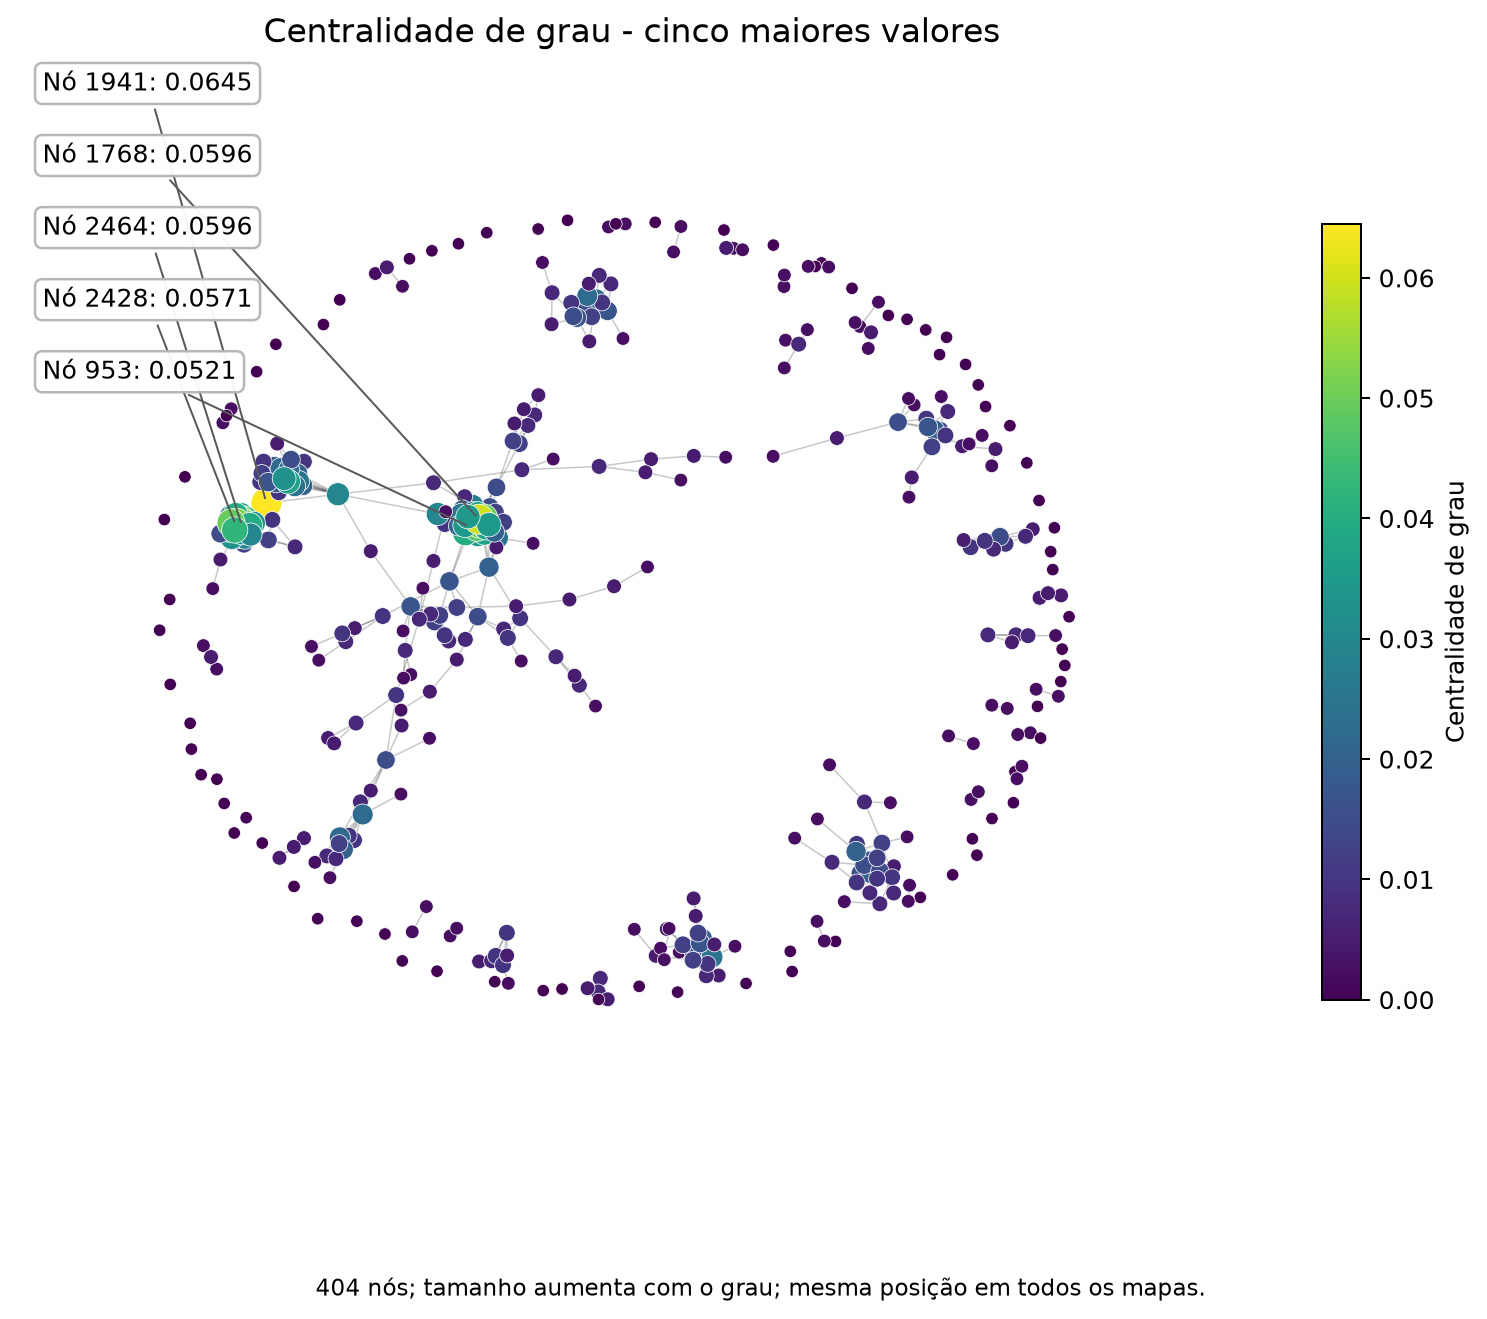

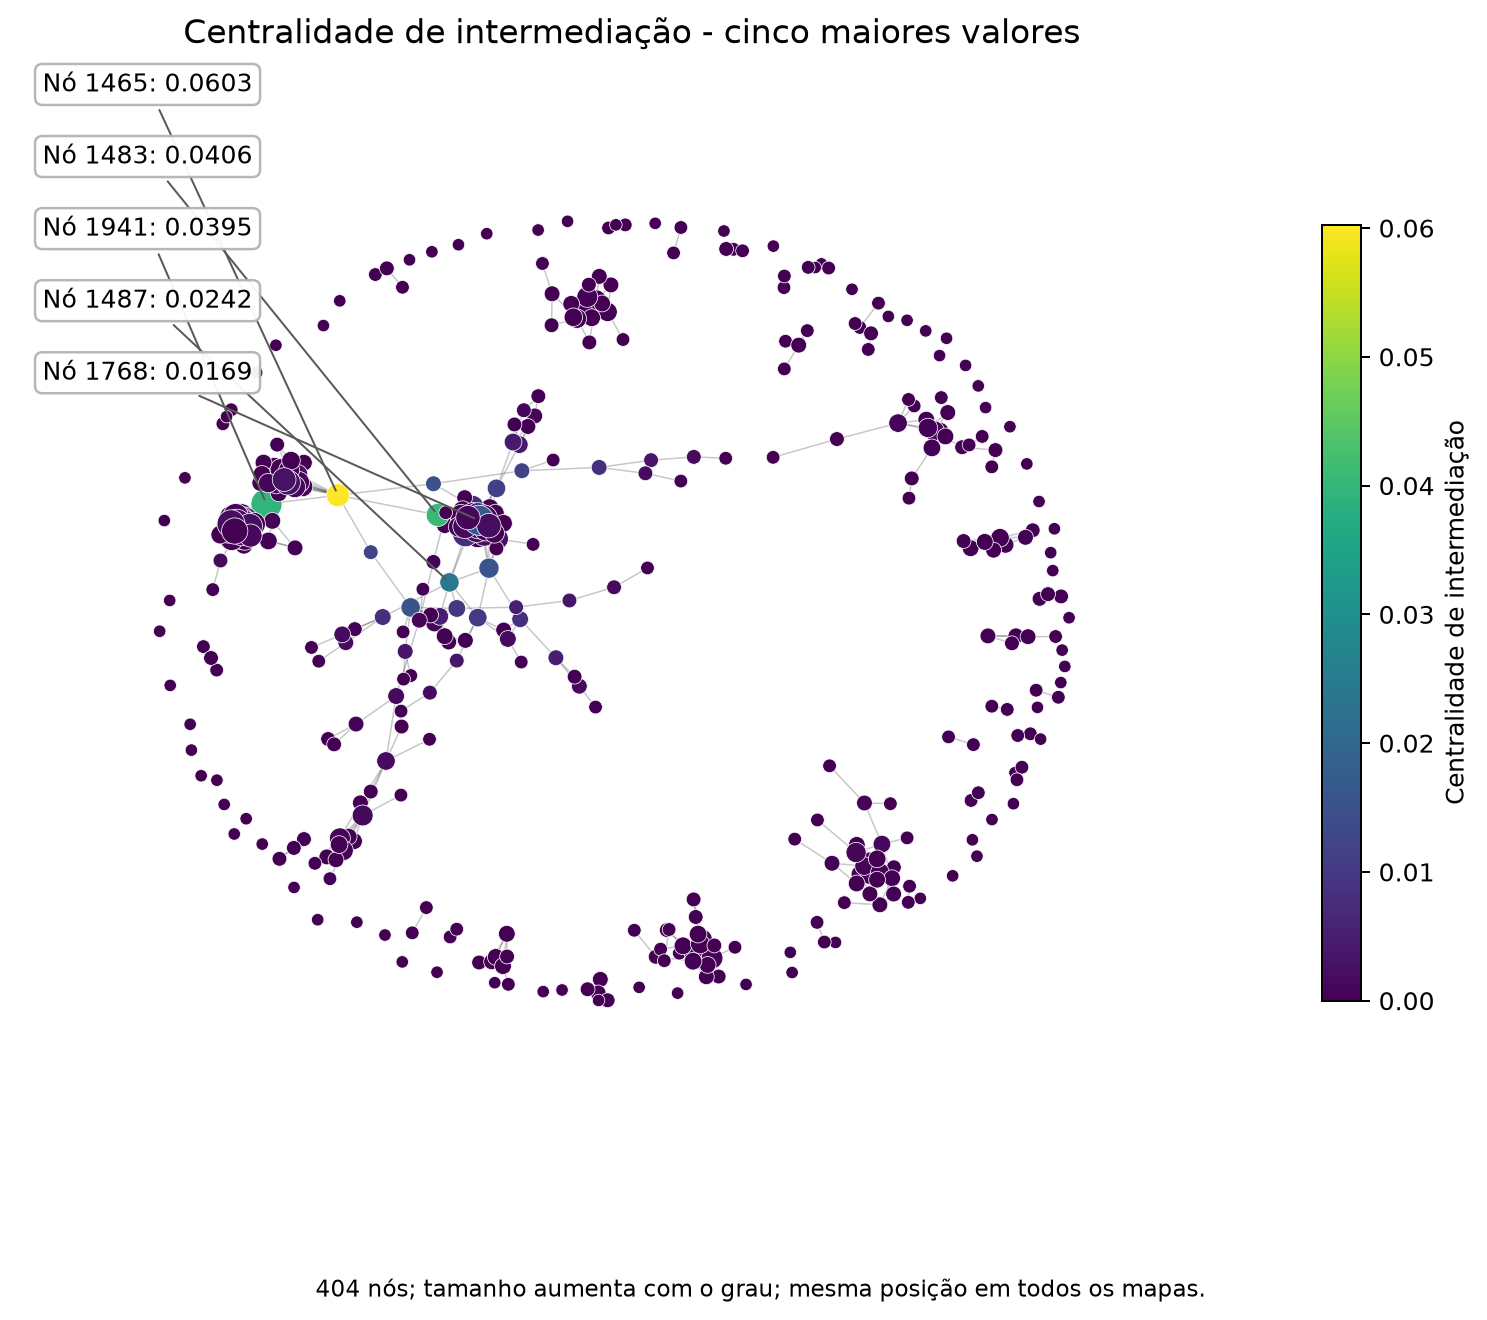

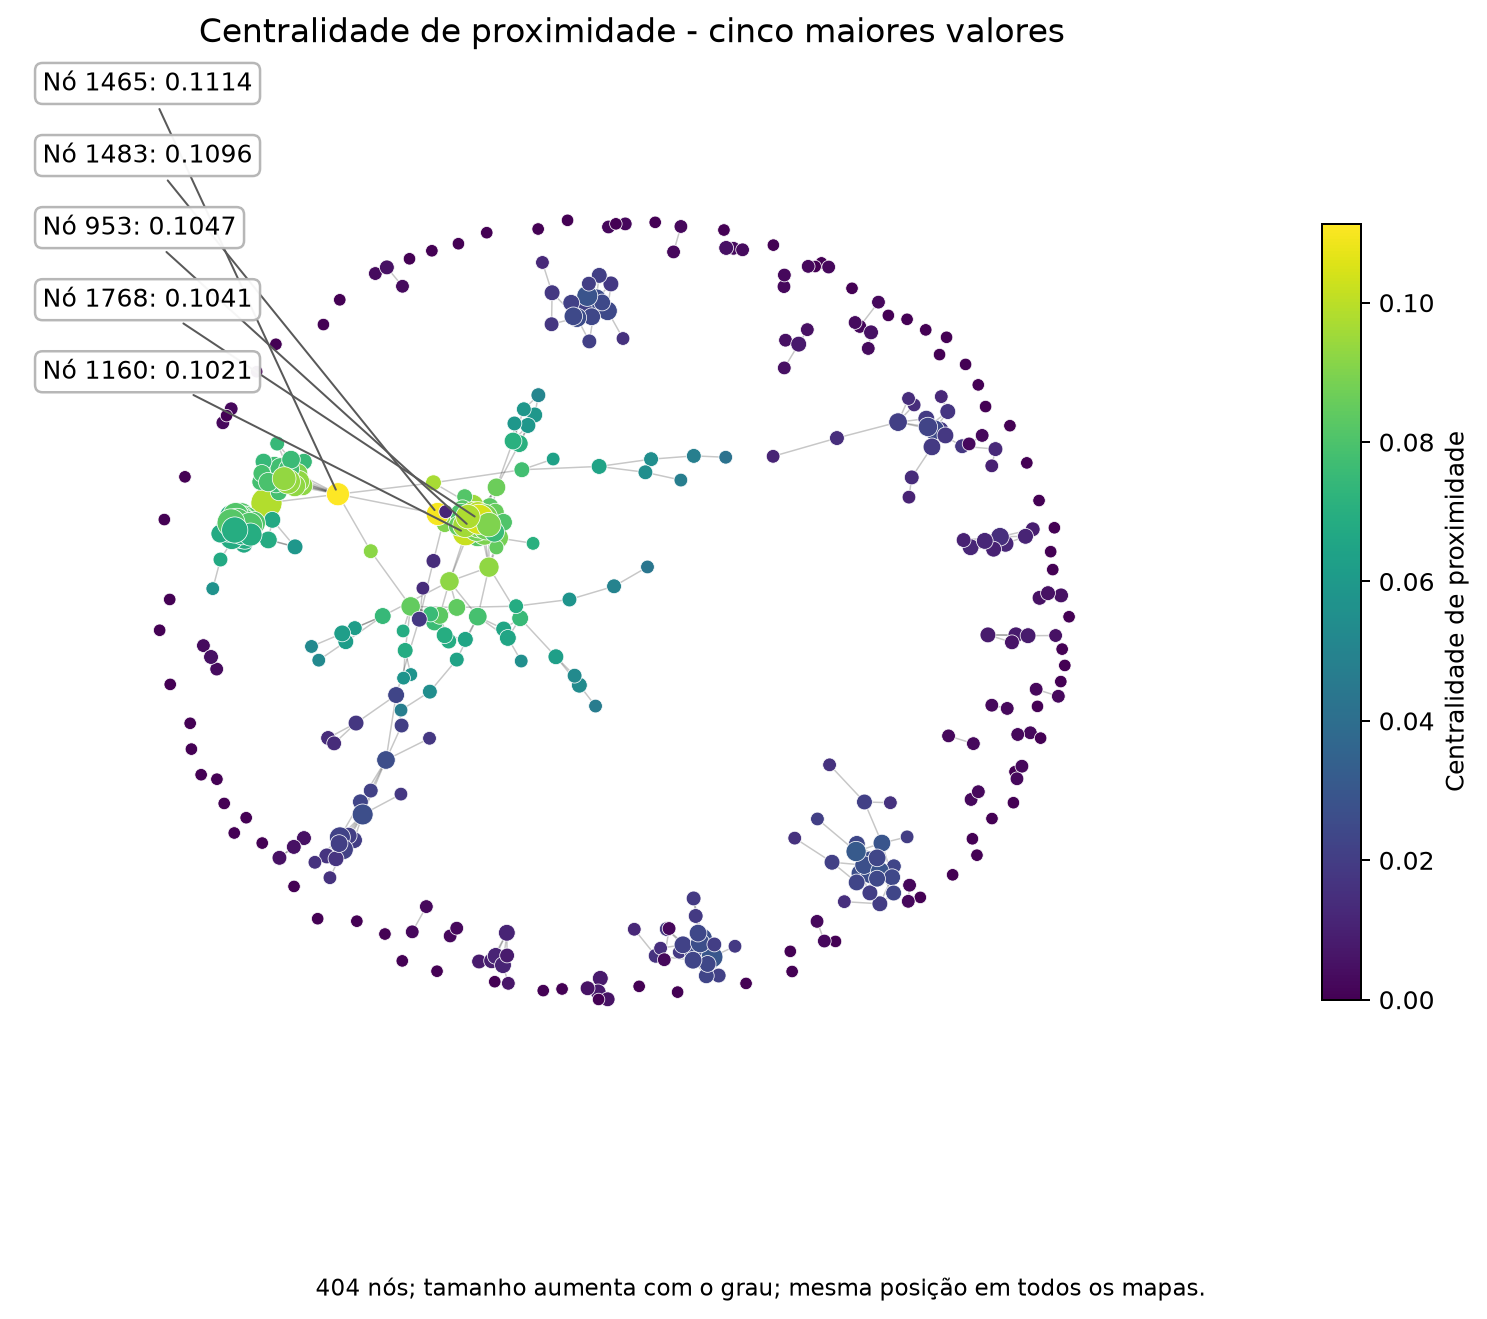

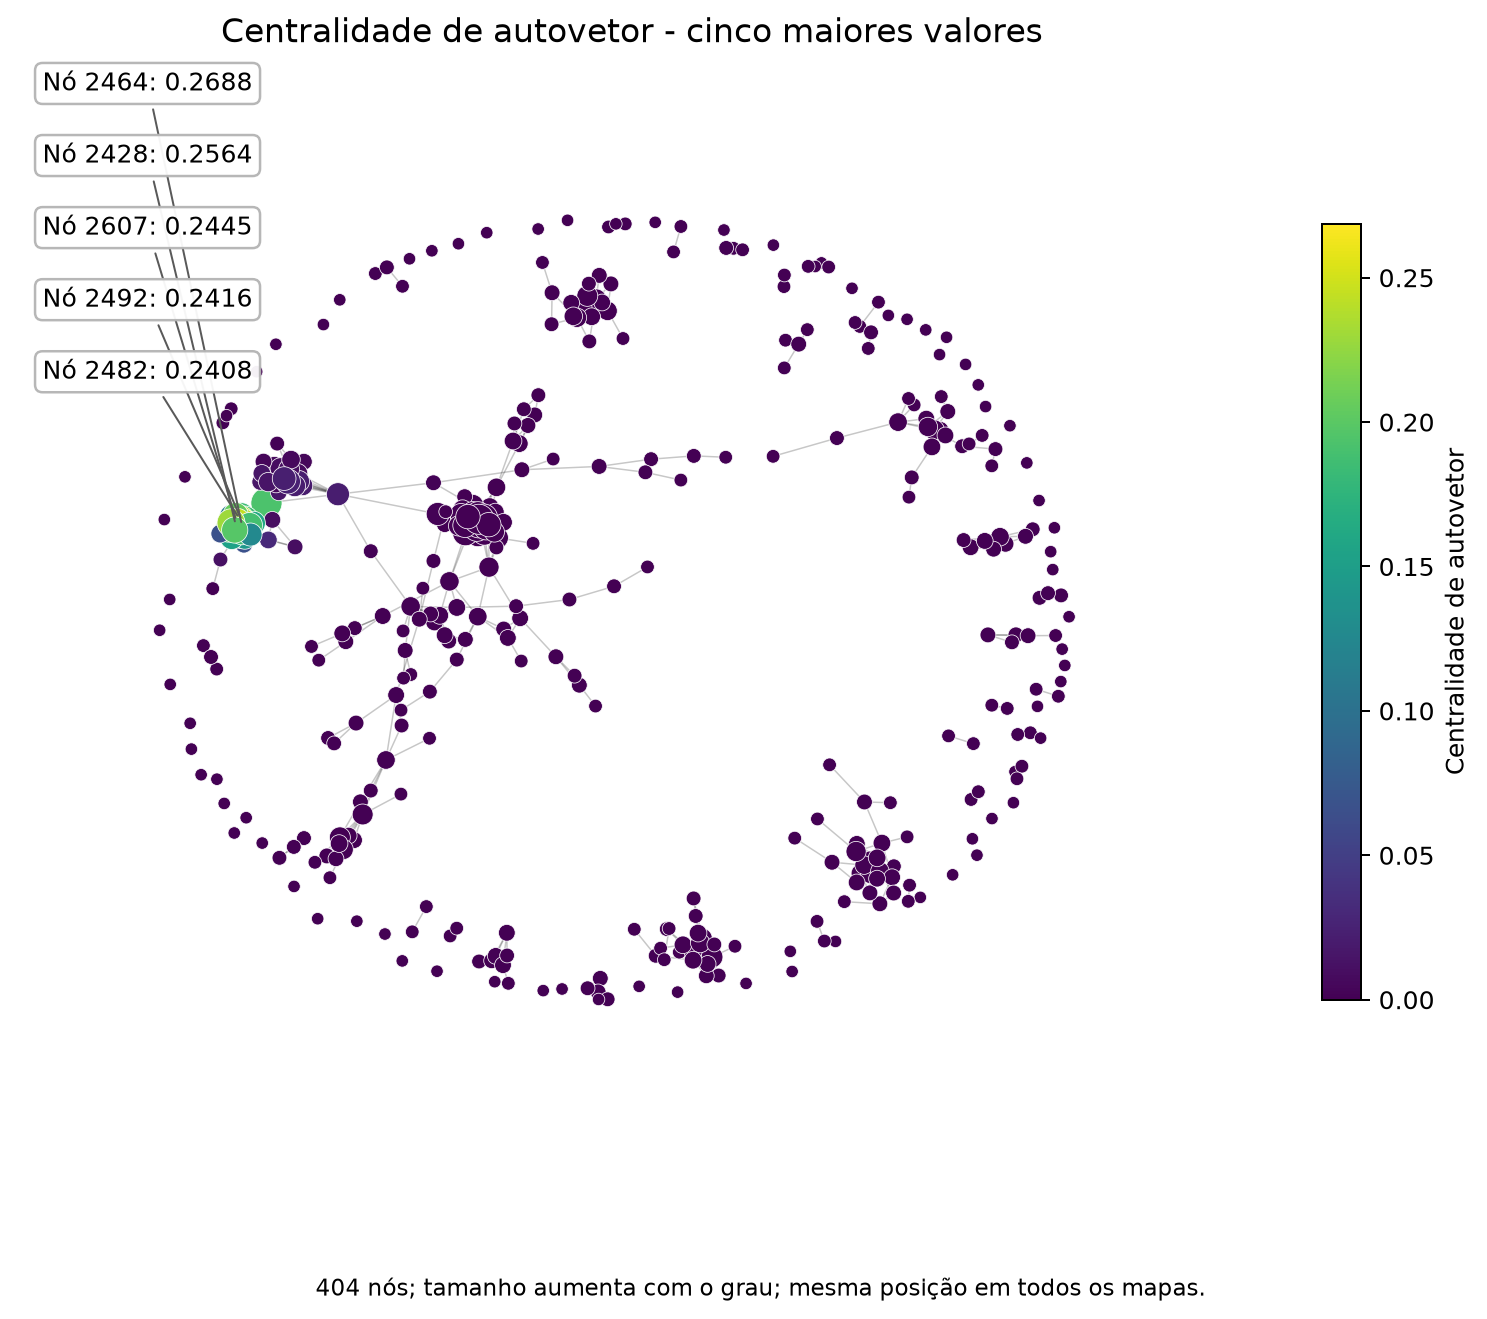

In [25]:
posicoes = nx.spring_layout(grafo, seed=SEMENTE, k=0.28, iterations=200)
pasta_figuras = PASTA_RESULTADOS / "figuras"
plotar_metricas(grafo, tabela_metricas, posicoes, pasta_figuras)
for metrica in METRICAS:
    display(Image(filename=str(pasta_figuras / f"{metrica}.png"), width=900))

### Mapa das comunidades
Cada comunidade não unitária tem uma cor na legenda. Os isolados aparecem em cinza para
simplificar o mapa, mas **cada um deles pertence a uma comunidade diferente**. As atribuições
individuais estão em `metricas.csv`. A fragmentação do grafo também contribui para a modularidade.

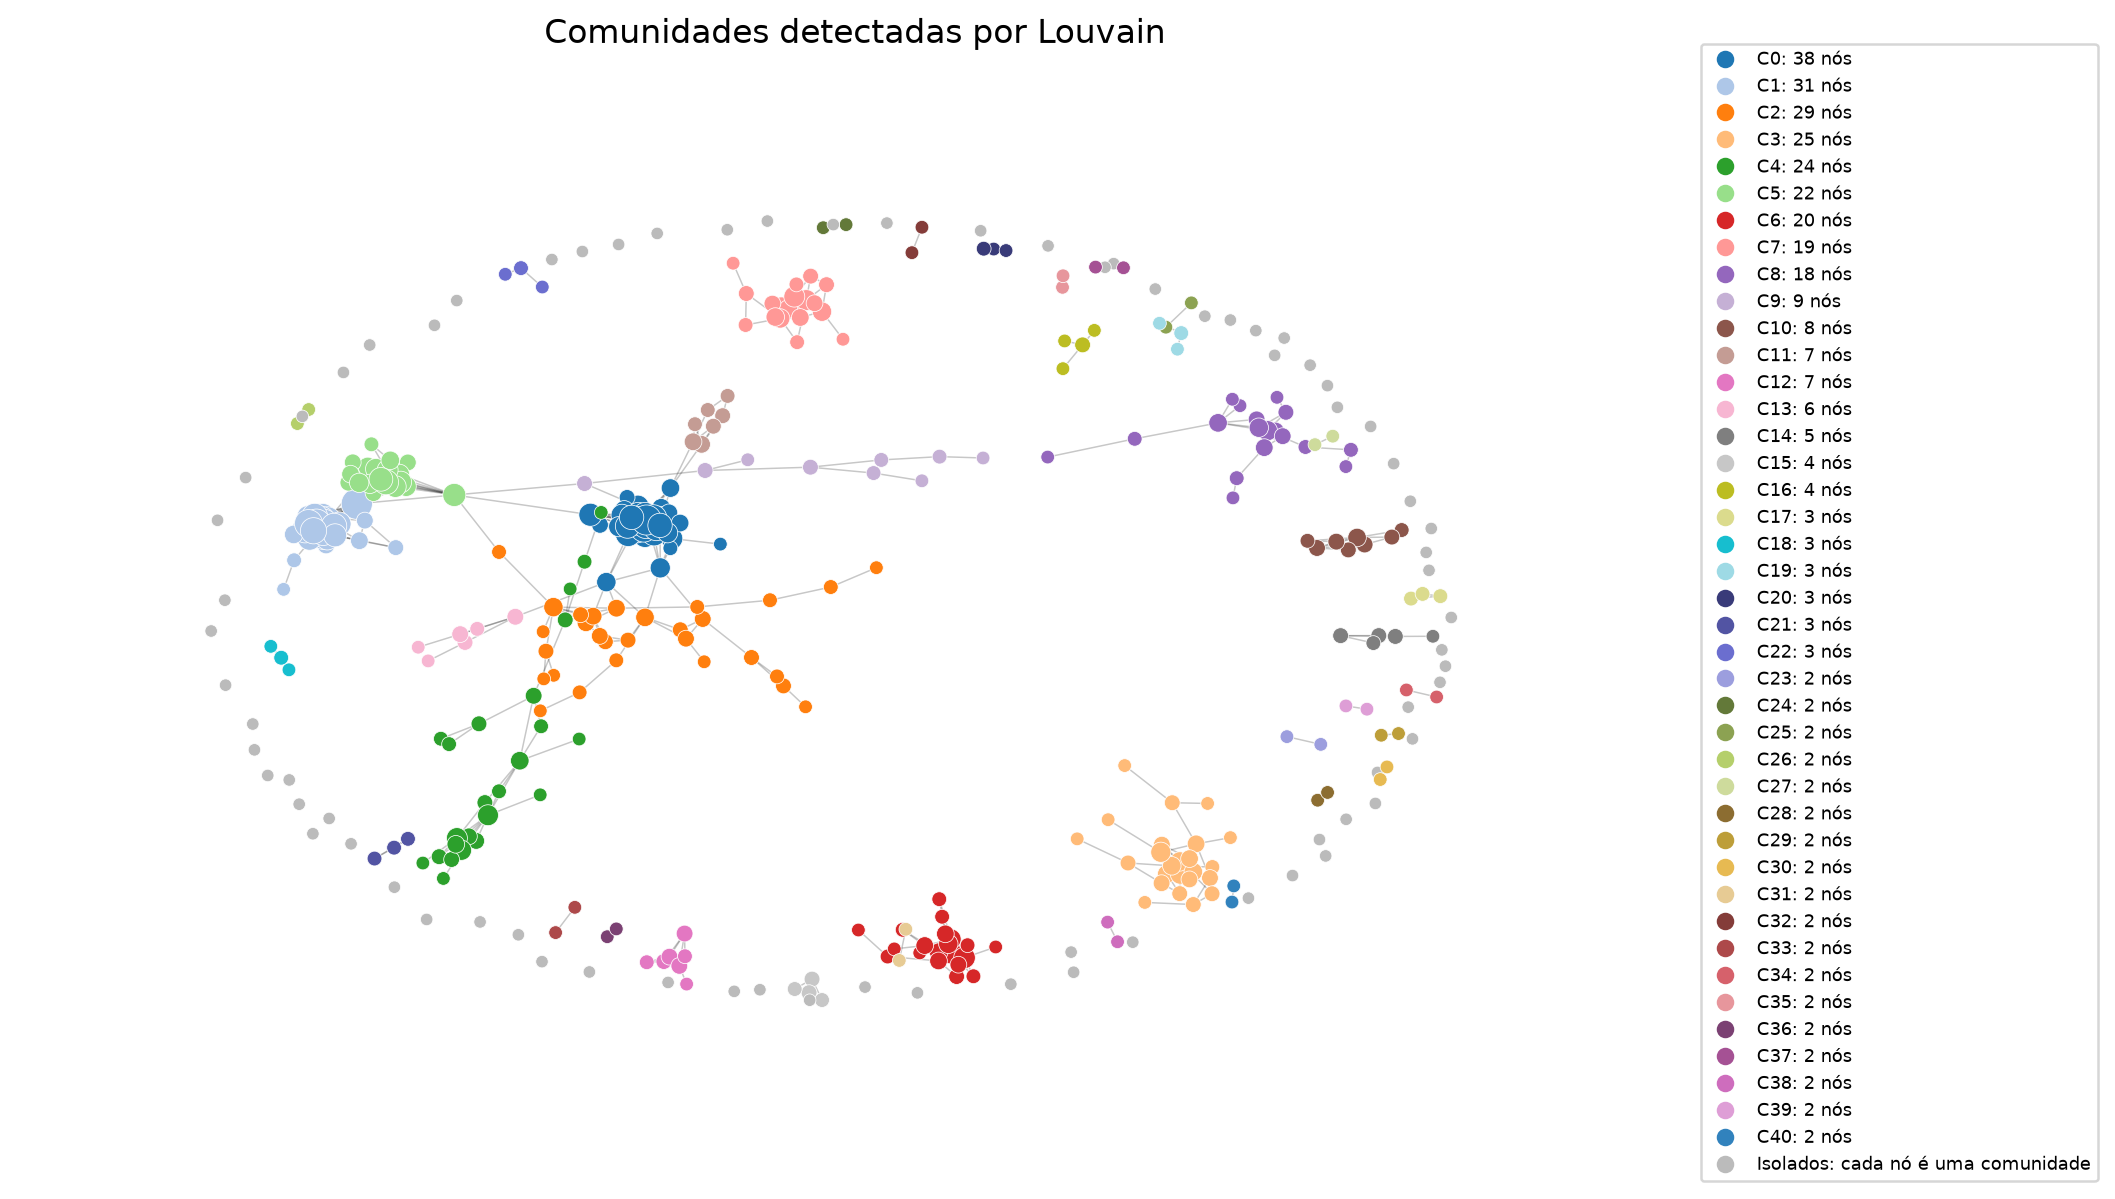

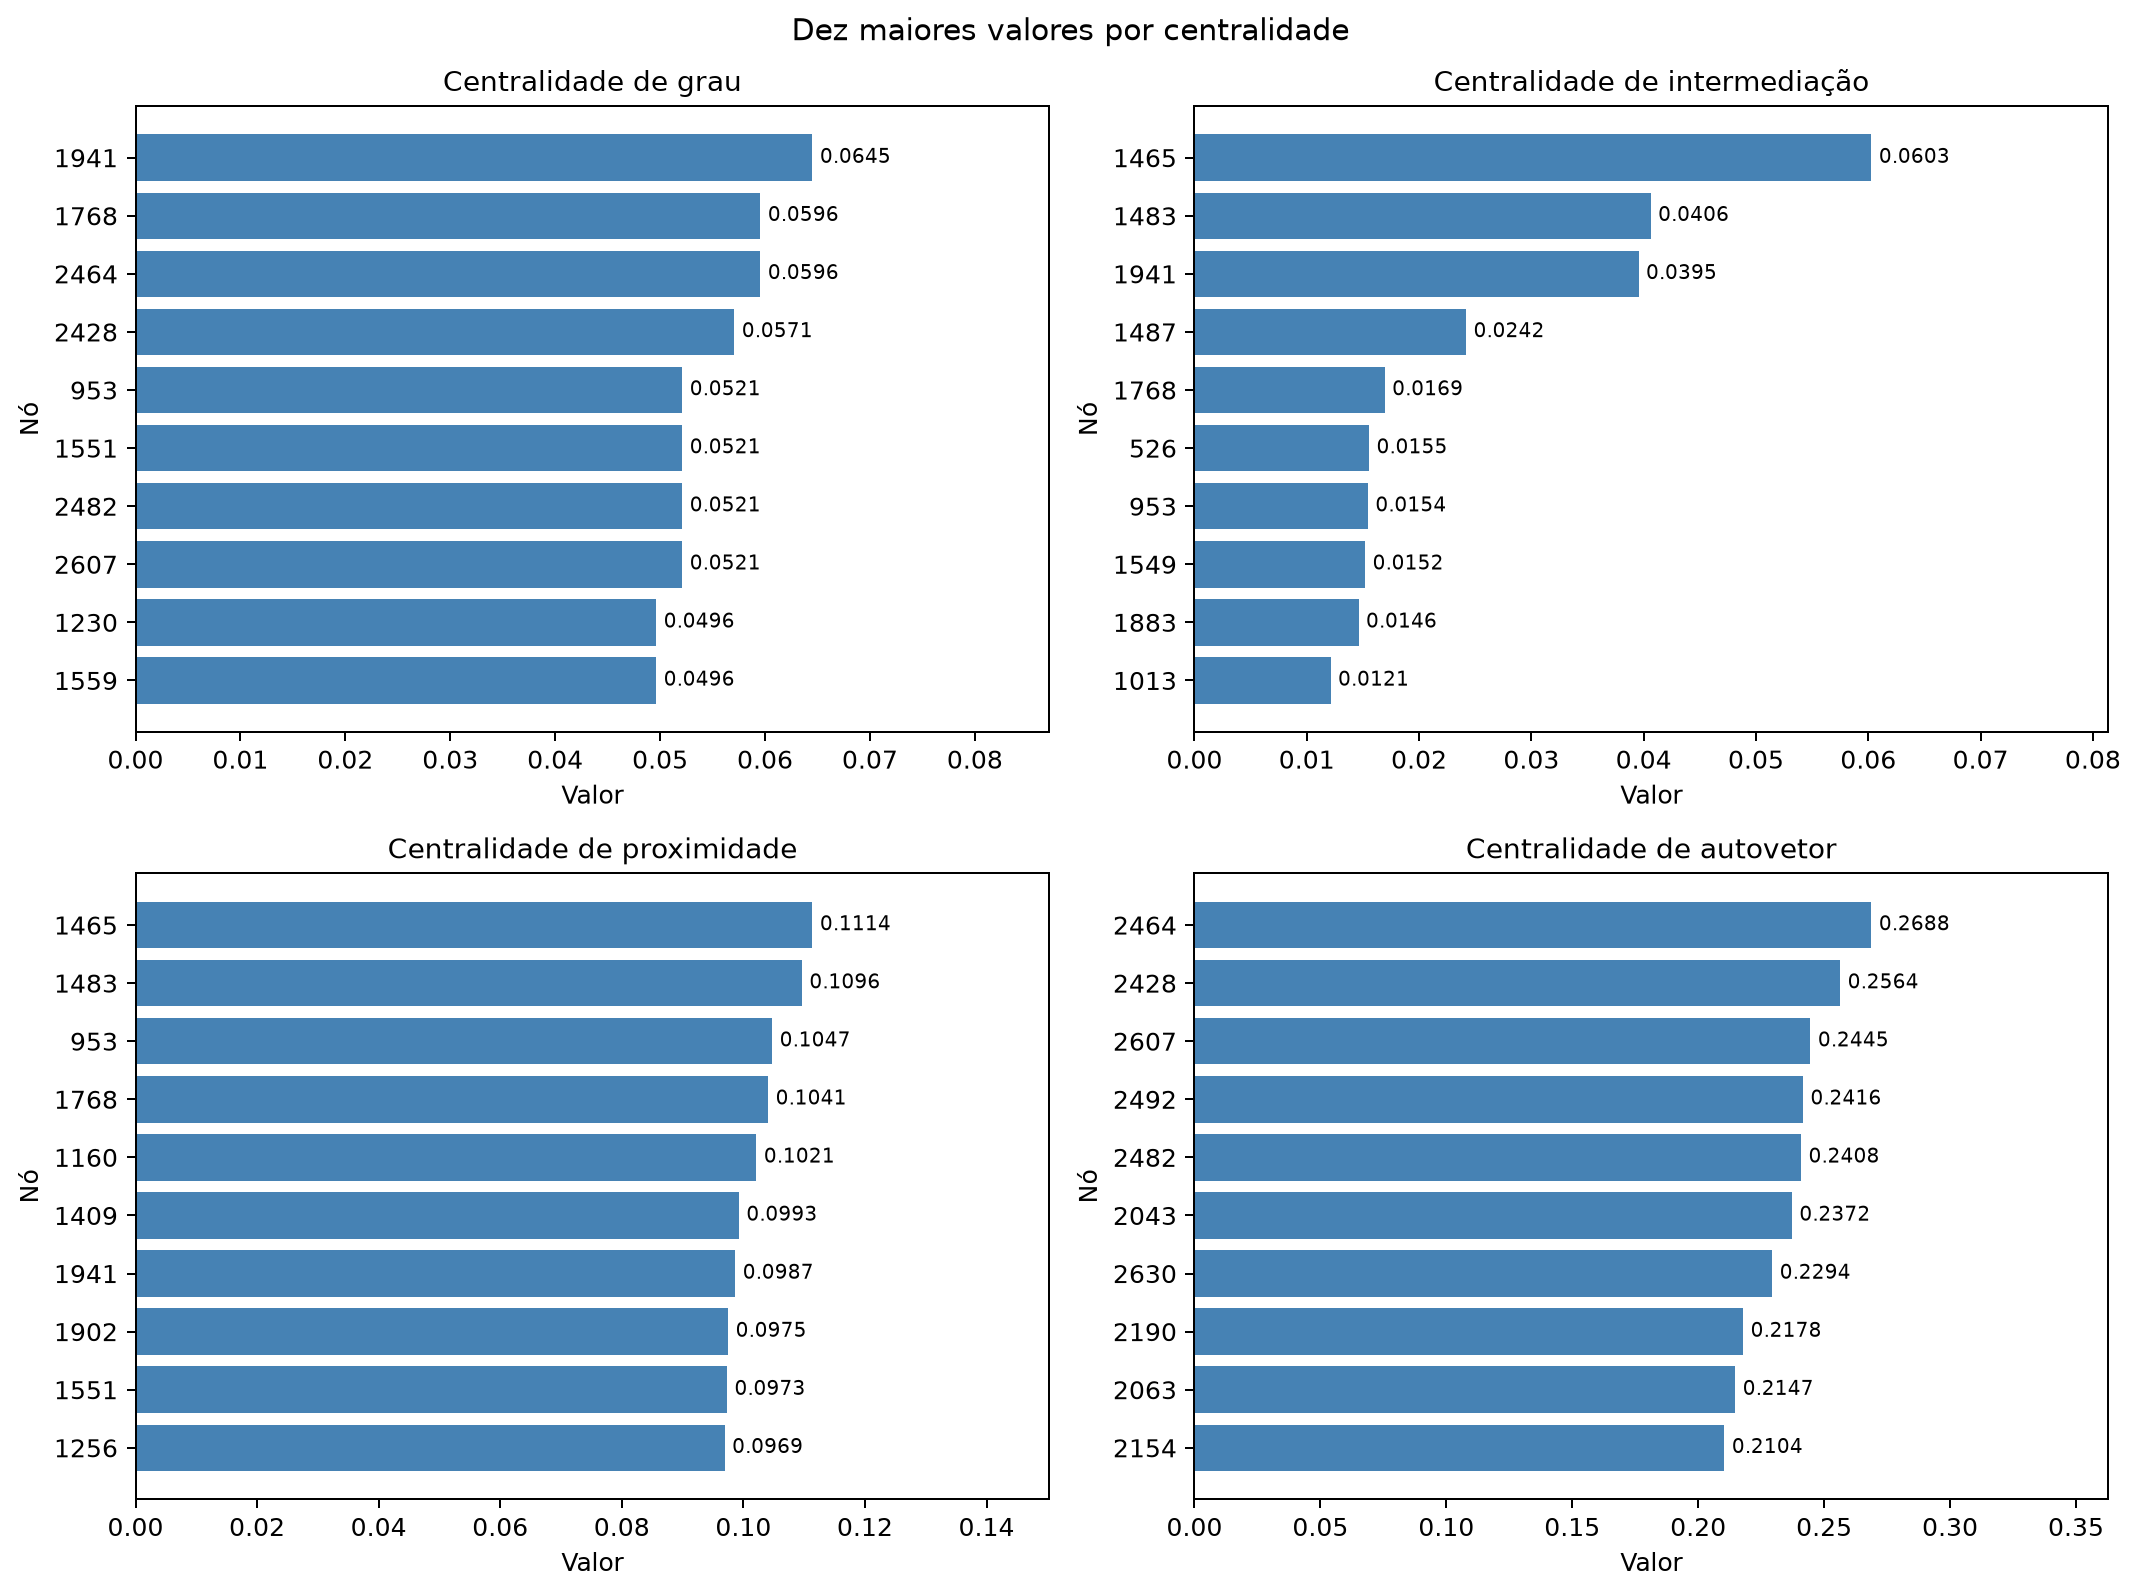

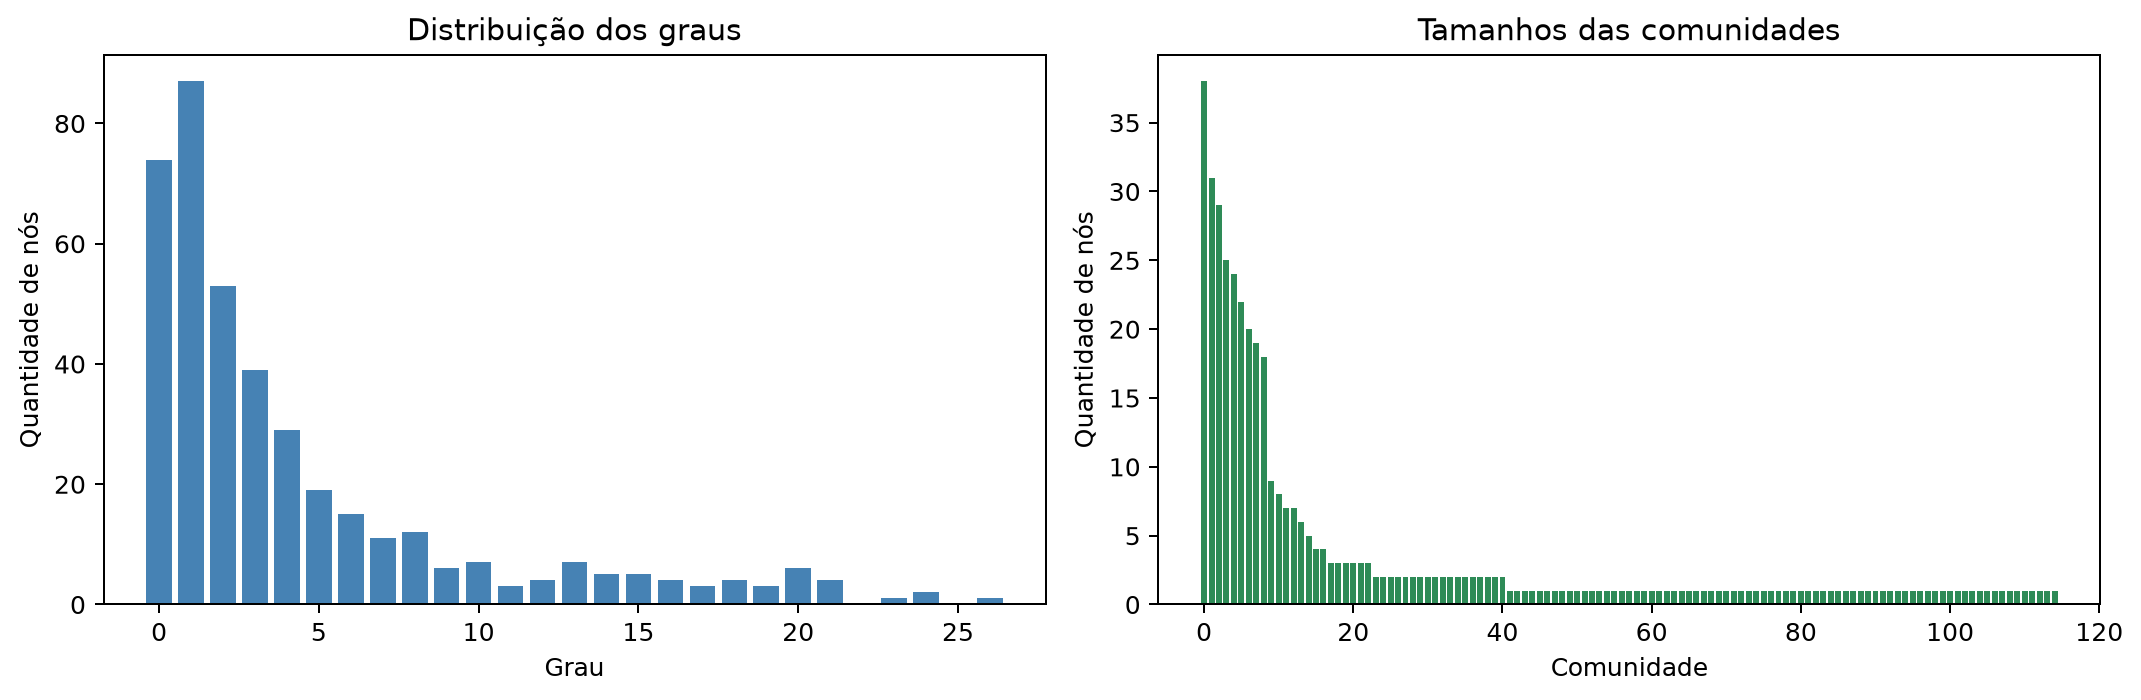

In [26]:
plotar_comunidades(grafo, tabela_metricas, tabela_comunidades, posicoes, pasta_figuras)
display(Image(filename=str(pasta_figuras / "comunidades.png"), width=1000))
plotar_resumos(tabela_metricas, tabela_comunidades, pasta_figuras)
display(Image(filename=str(pasta_figuras / "rankings.png"), width=1000))
display(Image(filename=str(pasta_figuras / "distribuicoes.png"), width=1000))

## 6. Análise dos resultados
Com a semente 2026, o nó **1684** lidera grau, intermediação e proximidade. Tem 73 vizinhos
entre os sorteados e está numa componente de 75 nós. É um candidato a alcançar muitos usuários
diretamente e aparece em muitos caminhos mínimos da sua componente. Isso não implica acesso
às outras componentes.

O nó **2543** lidera autovetor, numa componente de 69 nós. Sua posição se destaca pelas conexões
com usuários também centrais. O autovetor global ficou concentrado nessa componente; por isso,
a comparação com os líderes de grau exige cuidado.

Louvain encontrou **104 comunidades**, incluindo **70 isolados**, com modularidade de aproximadamente
**0,821826**. A maior comunidade tem 75 nós. A modularidade elevada não prova por si só a existência
de grupos sociais reais: a amostra já tem 100 componentes desconectadas.

Se uma mensagem fosse transmitida apenas pelas amizades amostradas, não sairia da componente de
origem. As centralidades indicam potencial estrutural; não fizemos uma simulação de propagação.
A amostra remove vizinhos, então estes resultados não devem ser generalizados para toda a rede.
Os identificadores são anônimos, sem informação sobre quem são as pessoas.

Se o grupo trocar a semente, execute todas as células novamente e revise esta análise e o relatório.

## Entrega e demonstração
- Notebook executado, comentado, com os nomes e matrículas completos.
- Mini-relatório de até cinco páginas, em `output/pdf/relatorio.pdf`.
- O PDF usa mapas vetoriais TikZ com fonte serifada e legenda em colunas.
- Tabelas e imagens em `resultados/`; os PNG permitem mostrar os valores com maior resolução.
- Para a demonstração: explicar a reconstrução, o sorteio, a fragmentação, os líderes de cada
  centralidade e a diferença entre comunidade e componente conexa.

O relatório é escrito em LaTeX, com gráficos vetoriais, em formato acadêmico baseado na ABNT. Para recriar o PDF após executar as células, rode `python gerar_relatorio.py` com Tectonic instalado. Para gerar somente o `.tex` e compilá-lo no Overleaf, use `python gerar_relatorio.py --somente-tex`. Edite o texto permanente em `relatorio_base.tex`.

## Referências
- [SNAP: Social circles - Facebook](https://snap.stanford.edu/data/egonets-Facebook.html).
- McAuley e Leskovec. *Learning to Discover Social Circles in Ego Networks*. NIPS, 2012.
- Blondel et al. *Fast unfolding of communities in large networks*. J. Stat. Mech., 2008, P10008.
- [NetworkX: centralidades](https://networkx.org/documentation/stable/reference/algorithms/centrality.html)
  e [Louvain](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.community.louvain.louvain_communities.html).